In [1]:
import numpy as np
import tensorflow as tf
from scipy.linalg import expm
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from qugradlab.systems.semiconducting.esr import SpinChain
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pulse_vqe_entanglement.dataclasses import SimulationConfig

In [3]:
def _initialise_x0(config: SimulationConfig) -> np.ndarray:
    """Initial control parameters drawn uniformly in [-1, 1]."""
    n = config.n_time_steps * config.n_J_channels
    x0 = config.J_init_scale * np.random.uniform(-1.0, 1.0, size=n) + config.J_init_mean
    return np.clip(x0, -1.0, 1.0)

def convert_dtype(np_array) -> tf.Tensor:
    """Convert numpy array to TensorFlow complex128 tensor."""
    return tf.cast(tf.convert_to_tensor(np_array), dtype=tf.complex128)


def single_qubit_excitation(theta: float) -> np.ndarray:
    """
    Single-qubit rotation gate in the two-spin subspace.

    Rotates the |01⟩ ↔ |10⟩ subspace by angle theta while leaving |00⟩ and
    |11⟩ unchanged. Basis order: [|00⟩, |01⟩, |10⟩, |11⟩].
    """
    return np.array(
        [[1, 0, 0, 0],
         [0, np.cos(theta), -np.sin(theta), 0],
         [0, np.sin(theta),  np.cos(theta), 0],
         [0, 0, 0, 1]],
        dtype=np.complex128,
    )

def _cost_entropy(driven_sys, x, *, S_max: float, ent_traj_fn) -> float:
    """
    Mean squared trajectory violation of the entanglement cap.

    cost = mean((E(t) - S_max)₊²) where E is computed by ent_traj_fn.

    Parameters
    ----------
    ent_traj_fn : callable
        A traj_fn from STATE_MEASURES: takes (4, n_t) trajectory, returns (n_t,).
    """
    traj = np.asarray(driven_sys.propagate_all(x))
    viol = np.maximum(0.0, ent_traj_fn(traj) - S_max)
    return float(np.mean(viol**2))


def _entropy_grad_fd(driven_sys, x, *, S_max: float, eps: float,
                     ent_traj_fn, f0: float | None = None) -> np.ndarray:
    """
    Forward-difference gradient of the entropy cost.

    Parameters
    ----------
    ent_traj_fn : callable
        Trajectory entanglement function; see _cost_entropy.
    f0 : float, optional
        Cost at the unperturbed x. Providing it avoids a redundant evaluation.
    """
    x = np.asarray(x, float)
    if f0 is None:
        f0 = _cost_entropy(driven_sys, x, S_max=S_max, ent_traj_fn=ent_traj_fn)
    g = np.empty_like(x)
    for i in range(len(x)):
        xp = x.copy()
        xp[i] += eps
        g[i] = (_cost_entropy(driven_sys, xp, S_max=S_max, ent_traj_fn=ent_traj_fn) - f0) / eps
    return g


def _lagrangian_and_grad(driven_sys, x, *, observable, lam, S_max, fd_eps,
                         rho, eps_infidelity, ent_traj_fn):
    """
    Augmented Lagrangian value and gradient.

    Objective: L = S_cost + λ(I - ε) + (ρ/2)(I - ε)²

    where S_cost is the mean-squared entanglement violation (using ent_traj_fn)
    and I is the state infidelity (the constraint I ≤ ε is enforced via λ).
    """
    S = _cost_entropy(driven_sys, x, S_max=S_max, ent_traj_fn=ent_traj_fn)
    gS = _entropy_grad_fd(driven_sys, x, S_max=S_max, eps=fd_eps, ent_traj_fn=ent_traj_fn, f0=S)

    infidelity, grad_inf = driven_sys.gradient(x, observable)
    infidelity = max(0.0, float(np.real(infidelity)))   # guard against float64 cancellation
    grad_inf = np.asarray(grad_inf, float)
    c = infidelity - eps_infidelity

    L = S + lam * c + 0.5 * rho * c**2
    gL = gS + (lam + rho * c) * grad_inf
    return float(L), gL


def _primal_dual_optimise(driven_sys, x0, *, observable, bounds, config: SimulationConfig,
                          ent_traj_fn, verbose: bool = True):
    """
    Augmented Lagrangian primal-dual loop.

    Each outer iteration minimises the Lagrangian via L-BFGS-B, then updates
    the dual variable λ ← max(0, λ + α(I - ε)).

    Parameters
    ----------
    ent_traj_fn : callable
        Trajectory entanglement function resolved from config.state_ent_measure.

    Returns
    -------
    x_final : np.ndarray
    lam_final : float
    history : list[dict]  – per-outer-iteration diagnostics
    """
    x = np.asarray(x0, float).copy()
    lam = 1.0
    hist = []

    for k in range(int(config.n_outer)):
        res = minimize(
            lambda z: _lagrangian_and_grad(
                driven_sys, z, observable=observable, lam=lam,
                S_max=float(config.S_max), fd_eps=float(config.fd_eps),
                rho=float(config.rho), eps_infidelity=float(config.eps_infidelity),
                ent_traj_fn=ent_traj_fn,
            ),
            x0=x, jac=True, method="L-BFGS-B", bounds=bounds,
            options={"maxiter": int(config.inner_maxiter), "gtol": float(config.gtol)},
        )
        x = np.asarray(res.x, float)

        S = _cost_entropy(driven_sys, x, S_max=float(config.S_max), ent_traj_fn=ent_traj_fn)

        infidelity = np.real(driven_sys.gradient(x, observable)[0])
        c = infidelity - float(config.eps_infidelity)
        lam = max(0.0, lam + float(config.dual_lr) * c)

        hist.append({
            "outer_iter": k, "lam": lam, "I_final": infidelity, "constraint_residual": c, "S": S,
            "inner_success": bool(res.success), "inner_nit": int(res.nit),
            "inner_fun": float(res.fun),
            "inner_grad_norm": float(np.linalg.norm(res.jac)) if res.jac is not None else np.nan,
            "message": str(res.message),
        })
        if verbose:
            print(f"[outer {k:02d}] I={infidelity:.3e}, lam={lam:.6e}, "
                  f"inner_nit={res.nit}, inner_success={res.success}, "
                  f"constraint_residual={c:.3e}, S={S:.3e}")

    return x, lam, hist

def von_neumann_entropy_single(state: np.ndarray) -> float:
    """
    Von Neumann entropy S(ρ_A) in bits for a 2-qubit pure state.

    Computes rho_A = Tr_B(|ψ⟩⟨ψ|) then S = -Tr(ρ_A log₂ ρ_A).
    """
    rho_A = state.reshape(2, 2) @ state.reshape(2, 2).conj().T
    eig = np.clip(np.linalg.eigvalsh(rho_A), 1e-15, 1.0)
    return float(-np.sum(eig * np.log2(eig)))


def von_neumann_entropy_traj(traj: np.ndarray) -> np.ndarray:
    """
    Von Neumann entropy S(ρ_A) in bits along a 2-qubit state trajectory.

    Parameters
    ----------
    traj : ndarray, shape (4, n_t)
        State at each time step.

    Returns
    -------
    ndarray, shape (n_t,)
    """
    psi = np.asarray(traj).T.reshape(-1, 2, 2)          # (n_t, 2, 2)
    rho_A = psi @ np.conj(psi).transpose(0, 2, 1)        # (n_t, 2, 2)
    eig = np.clip(np.linalg.eigvalsh(rho_A), 1e-15, 1.0)
    return -np.sum(eig * np.log2(eig), axis=1)

### First set config and optimise pulses without noise

Note:
1. Infidelity now must be the density matrix infidelity with noise
2. Need to change plotting functions respectively

In [4]:
config = SimulationConfig(
    zeeman_splittings=np.array([1000.0, 1008.0]),
    initial_state=np.array([1.0, 1.0, 0.0, 0.0]/np.sqrt(2), dtype=np.complex128),
    theta_target=0.1 * np.pi,
    n_time_steps=100,
    n_discretisation=1,
    T=1000.0,
    max_drive_strength=0.0,
    J_max=10.0,
    J_min=0.0,
    J_init_scale=1e0,
    J_init_mean=0.0,
    feromagnetic=False,
    gtol=1e-12,
    maxiter=500,
    entanglement_optimisation=True,
    state_ent_measure="von_neumann",
    #extra_ent_measures=["linear"],
    J_init_seed=None,

    noise_type="depolarising",
    noise_rate=0.0,

    # primal-dual settings
    S_max=0.01,
    eps_infidelity=1e-12,
    rho=0.0,
    dual_lr=1e10,
    n_outer=5,
    inner_maxiter=500,
    fd_eps=1e-6,
)

In [5]:
NS_TO_US = 1e-3

I2 = np.eye(2, dtype=np.complex128)
Splus = np.array([[0, 1], [0, 0]], dtype=np.complex128)
Sminus = np.array([[0, 0], [1, 0]], dtype=np.complex128)
X = np.array([[0, 1], [1, 0]], dtype=np.complex128)
Y = np.array([[0, -1j], [1j, 0]], dtype=np.complex128)
Z = np.array([[1.0, 0.0], [0.0, -1.0]], dtype=np.complex128)
Z1 = np.kron(Z, I2)
Z2 = np.kron(I2, Z)

B = np.array(config.zeeman_splittings, dtype=np.float64)
B_avg = np.mean(B)
deltaB = B - B_avg
U_rot = expm(-1j * np.pi 
                * (deltaB[0] * Z1 + deltaB[1] * Z2) 
                * config.T * NS_TO_US)

target_state = U_rot @ single_qubit_excitation(config.theta_target) @ config.initial_state
observable = np.eye(4, dtype=np.complex128) - np.outer(target_state, target_state.conj())

sys = SpinChain(
    spins=2,
    zeeman_splittings=deltaB,
    max_drive_strength=config.max_drive_strength,
    J_max=config.J_max,
    J_min=config.J_min,
    feromagnetic=config.feromagnetic,
    use_graph=True,
)

n_steps = config.n_time_steps
n_disc = config.n_discretisation
n_fine = n_steps * n_disc
dt_fine_us = (config.T / n_fine) * NS_TO_US

def pulse_function(x):
    x_coarse = tf.reshape(convert_dtype(x), (n_steps, config.n_J_channels))
    x_fine = tf.repeat(x_coarse, repeats=n_disc, axis=0)
    return (
        convert_dtype(np.zeros((n_fine, 2))),       # drive amplitudes (disabled)
        convert_dtype(config.zeeman_splittings),    # drive frequencies
        x_fine,                                     # J coupling amplitudes
        convert_dtype(config.initial_state),        # initial state
        dt_fine_us * 2 * np.pi,                     # timestep (rad/μs)
    )

driven_sys = sys.pulse_form(pulse_function)

x0 = _initialise_x0(config)
bounds = [(-1.0, 1.0)] * len(x0)

In [6]:
res = minimize(
    driven_sys.gradient, x0, args=(observable,),
    jac=True, bounds=bounds, method="L-BFGS-B",
    options={"maxiter": int(config.maxiter), "gtol": float(config.gtol)},
)
gn = float(np.linalg.norm(res.jac)) if res.jac is not None else 0.0
S = _cost_entropy(driven_sys, res.x, S_max=float(config.S_max), ent_traj_fn=von_neumann_entropy_traj)
print(f"Infidelity: I={res.fun:.3e}, nit={res.nit}, success={res.success}, grad_norm={gn:.3e}, S={S:.3e}")

xf = res.x
infidelity_baseline_xf = float(res.fun)
print(xf)
print(infidelity_baseline_xf)

Tracing control amplitude graph.
Infidelity: I=2.781e-16, nit=9, success=True, grad_norm=1.417e-08, S=4.644e-02
[-0.69881982 -0.912623   -0.99999508  0.5857921  -0.84516793 -0.5268903
 -0.32548891 -0.17807323  0.0521542  -0.11173727  0.25840535  0.04758501
  0.38688303 -0.56763235 -0.86567313 -0.30022782  0.0122529  -0.25112399
  0.99859629 -0.86191235 -0.1849835  -0.6323432   0.51635169  0.44840092
  0.52831459  0.22407412 -0.19185571  0.48939791 -0.5098735  -0.86606609
 -0.14035969  0.70360881 -0.9140019  -0.65432545 -0.69485624 -0.29859011
  0.61773298 -0.1098484   0.80244529 -0.02629761 -0.30144692 -0.74848224
  0.31122116  0.24014805 -0.04051716  0.68383019  0.03955919  0.52564337
  0.83129504  0.39782572 -0.49275431  0.52380325 -0.05919215 -0.11463644
  0.1083601  -0.40937693 -0.94889512 -0.55672976 -0.79430456 -0.24841508
  0.77836563  0.2253486  -0.51058604 -0.96859795 -0.72901346 -0.25895983
 -0.86840139  0.59408714 -0.62255614 -0.95941408  0.78832569  0.09537502
  0.34302365 

In [7]:
xf_ent, lam, hist = _primal_dual_optimise(
            driven_sys, x0, observable=observable, bounds=bounds,
            config=config, ent_traj_fn=von_neumann_entropy_traj, verbose=True,
        )
infidelity_baseline_xf_ent = float(hist[-1]["I_final"])
print(xf_ent)
print(infidelity_baseline_xf_ent)

[outer 00] I=7.783e-05, lam=7.782712e+05, inner_nit=442, inner_success=True, constraint_residual=7.783e-05, S=1.576e-02
[outer 01] I=3.824e-16, lam=7.782712e+05, inner_nit=6, inner_success=True, constraint_residual=-9.996e-13, S=1.593e-02
[outer 02] I=4.592e-16, lam=7.782712e+05, inner_nit=1, inner_success=True, constraint_residual=-9.995e-13, S=1.593e-02
[outer 03] I=4.135e-16, lam=7.782712e+05, inner_nit=1, inner_success=True, constraint_residual=-9.996e-13, S=1.593e-02
[outer 04] I=4.135e-16, lam=7.782711e+05, inner_nit=0, inner_success=False, constraint_residual=-9.996e-13, S=1.593e-02
[ 0.15407552 -0.9999528  -0.86341904 -0.56364124 -0.35884352 -0.26110317
 -0.19454024 -0.1657366  -0.13409936 -0.09804486 -0.10983623 -0.10746081
 -0.10455263 -0.10499889 -0.09172488 -0.06324148 -0.11091615 -0.11376314
 -0.09347018 -0.06939623 -0.09707602 -0.09013439 -0.11643601 -0.09581493
 -0.08030707 -0.10298145 -0.10384875 -0.07416507 -0.08045288 -0.12214176
 -0.07859575 -0.07757064 -0.10603771 -

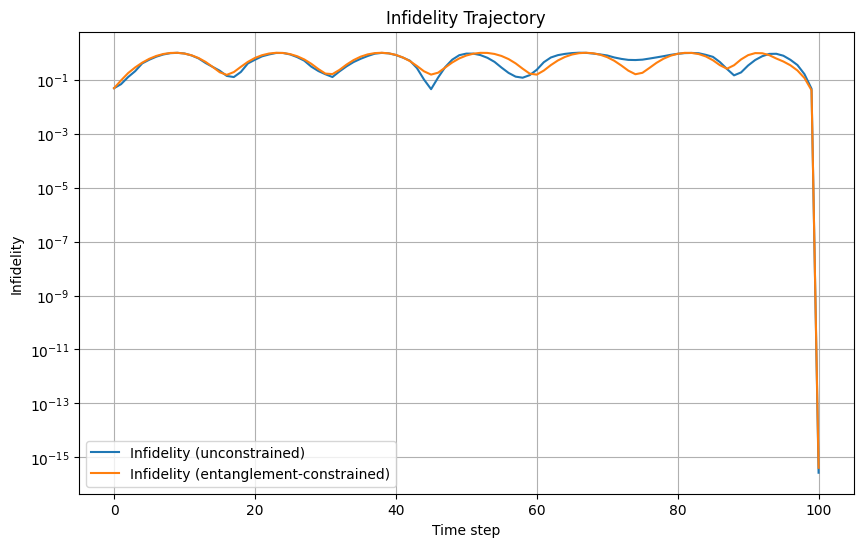

In [8]:
infidelity_xf = np.abs(driven_sys.evolved_expectation_value_all(xf, observable))
infidelity_xf_ent = np.abs(driven_sys.evolved_expectation_value_all(xf_ent, observable))

plt.figure(figsize=(10, 6))
plt.plot(infidelity_xf, label="Infidelity (unconstrained)")
plt.plot(infidelity_xf_ent, label="Infidelity (entanglement-constrained)")
plt.xlabel("Time step")
plt.ylabel("Infidelity")
plt.yscale("log")
plt.title("Infidelity Trajectory")
plt.legend()
plt.grid()
plt.show()

### Now add Lindbladian dynamics

Tracing control amplitude graph.


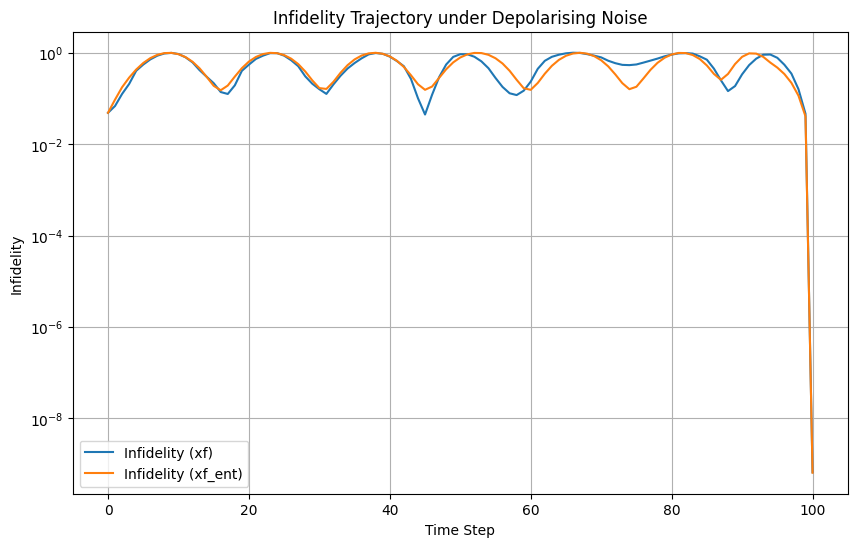

In [10]:
def local_depolarising_ops_2q(gamma):

    return np.array([
        np.sqrt(gamma/4) * np.kron(X, I2),
        np.sqrt(gamma/4) * np.kron(Y, I2),
        np.sqrt(gamma/4) * np.kron(Z, I2),
        np.sqrt(gamma/4) * np.kron(I2, X),
        np.sqrt(gamma/4) * np.kron(I2, Y),
        np.sqrt(gamma/4) * np.kron(I2, Z),
    ], dtype=np.complex128)

L0 = local_depolarising_ops_2q(1e-10)

sys_noisy = sys.add_lindblad_terms(L0=L0)

def Lindblad_pulse_function(x):
    x_coarse = tf.reshape(convert_dtype(x), (n_steps, config.n_J_channels))
    x_fine = tf.repeat(x_coarse, repeats=n_disc, axis=0)
    psi0 = config.initial_state
    return (
        convert_dtype(np.zeros((n_fine, 2))),       # drive amplitudes (disabled)
        convert_dtype(config.zeeman_splittings),    # drive frequencies
        convert_dtype(x_fine),                      # J coupling amplitudes
        convert_dtype(np.outer(psi0, psi0.conj())), # initial state (density matrix)
        convert_dtype(dt_fine_us * 2 * np.pi),      # timestep (rad/μs)
    )

driven_sys_noisy = sys_noisy.pulse_form(Lindblad_pulse_function)

final_state_noisy_xf = driven_sys_noisy.propagate_all(xf)
final_state_noisy_xf_ent = driven_sys_noisy.propagate_all(xf_ent)

def dm_infidelity(rho, target_psi):
    target_rho = np.outer(target_psi, target_psi.conj())
    return 1.0 - np.real(np.trace(rho @ target_rho))
    #return 1.0 - np.abs(np.trace(rho @ target_rho))

infidelity_xf = [dm_infidelity(final_state_noisy_xf[:,:,i], target_state) for i in range(final_state_noisy_xf.shape[2])]
infidelity_xf_ent = [dm_infidelity(final_state_noisy_xf_ent[:,:,i], target_state) for i in range(final_state_noisy_xf_ent.shape[2])]

plt.figure(figsize=(10, 6))
plt.plot(np.array(infidelity_xf), label='Infidelity (xf)')
plt.plot(np.array(infidelity_xf_ent), label='Infidelity (xf_ent)')
plt.yscale('log')
plt.xlabel('Time Step')
plt.ylabel('Infidelity')
plt.title('Infidelity Trajectory under Depolarising Noise')
plt.legend()
plt.grid()
plt.show()

Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.


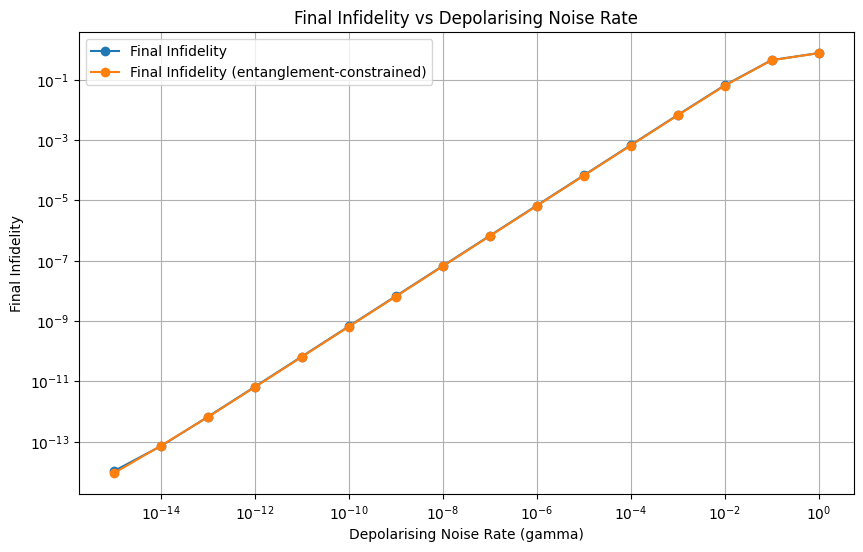

In [ ]:
# Plot final infidelity vs noise rate

noise_rates = np.logspace(-15, 0, num=16)
final_infidelities_xf = []
final_infidelities_xf_ent = []

for gamma in noise_rates:
    L0 = local_depolarising_ops_2q(gamma)
    sys_noisy = sys.add_lindblad_terms(L0=L0)
    driven_sys_noisy = sys_noisy.pulse_form(Lindblad_pulse_function)

    final_state_noisy_xf = driven_sys_noisy.propagate(xf)
    final_state_noisy_xf_ent = driven_sys_noisy.propagate(xf_ent)

    final_infidelity_xf = dm_infidelity(final_state_noisy_xf, target_state)
    final_infidelity_xf_ent = dm_infidelity(final_state_noisy_xf_ent, target_state)

    final_infidelities_xf.append(final_infidelity_xf)
    final_infidelities_xf_ent.append(final_infidelity_xf_ent)

plt.figure(figsize=(10, 6))
plt.plot(noise_rates, np.array(final_infidelities_xf) - infidelity_baseline_xf, marker='o', label='Final Infidelity')
plt.plot(noise_rates, np.array(final_infidelities_xf_ent) - infidelity_baseline_xf_ent, marker='o', label='Final Infidelity (entanglement-constrained)')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Depolarising Noise Rate (gamma)')
plt.ylabel('Final Infidelity')
plt.title('Final Infidelity vs Depolarising Noise Rate')
plt.legend()
plt.grid()
plt.show() 

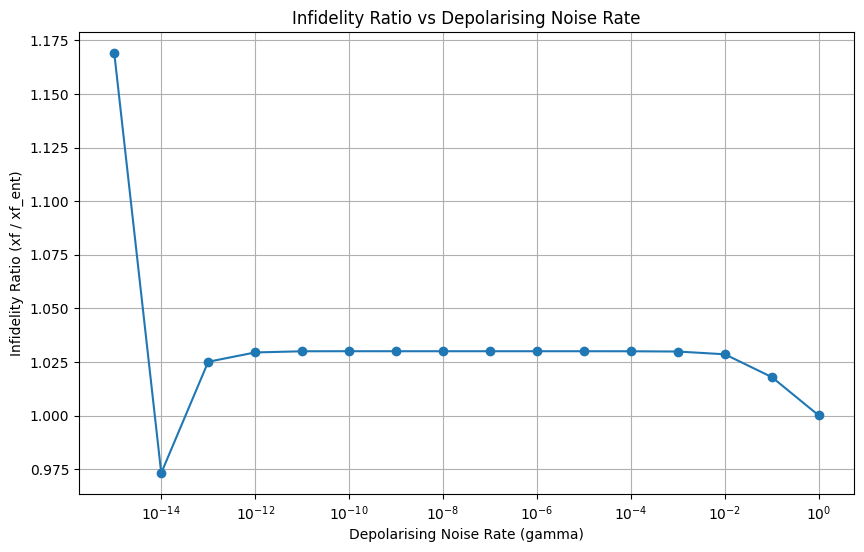

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(noise_rates, (np.array(final_infidelities_xf)-infidelity_baseline_xf) / (np.array(final_infidelities_xf_ent)-infidelity_baseline_xf_ent), marker='o')
plt.xscale('log')
plt.xlabel('Depolarising Noise Rate (gamma)')
plt.ylabel('Infidelity Ratio (xf / xf_ent)')
plt.title('Infidelity Ratio vs Depolarising Noise Rate')
plt.grid()
plt.show()

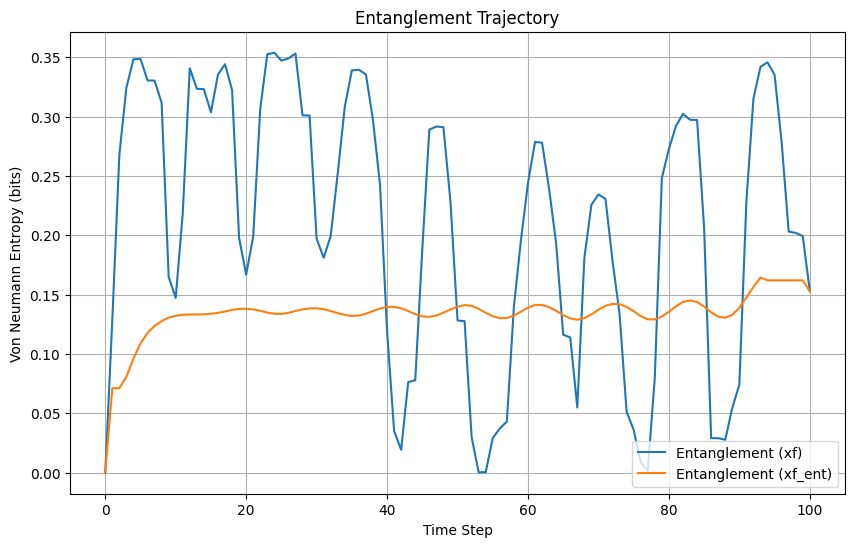

In [ ]:
traj_xf = driven_sys.propagate_all(xf)
traj_xf_ent = driven_sys.propagate_all(xf_ent)

S_xf = von_neumann_entropy_traj(traj_xf)
S_xf_ent = von_neumann_entropy_traj(traj_xf_ent)

plt.figure(figsize=(10, 6))
plt.plot(S_xf, label='Entanglement (xf)')
plt.plot(S_xf_ent, label='Entanglement (xf_ent)')
plt.xlabel('Time Step')
plt.ylabel('Von Neumann Entropy (bits)')
plt.title('Entanglement Trajectory')
plt.legend()
plt.grid()
plt.show()

Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.


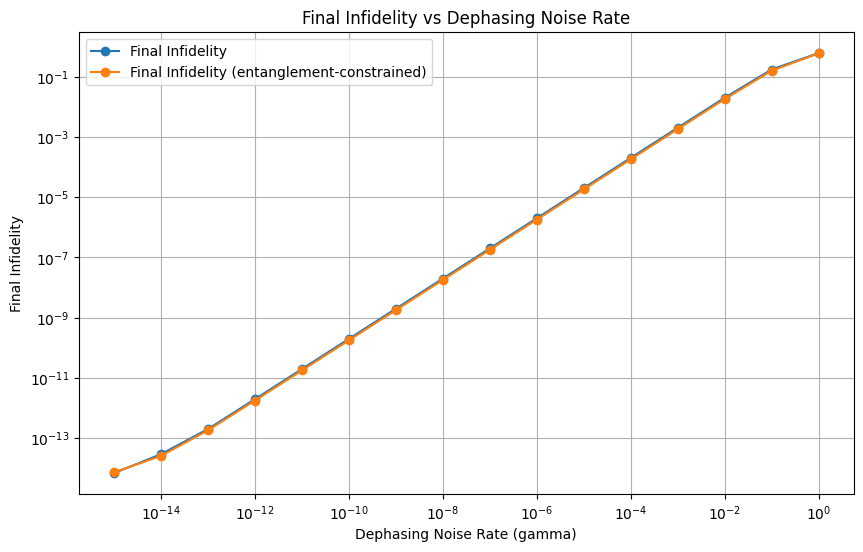

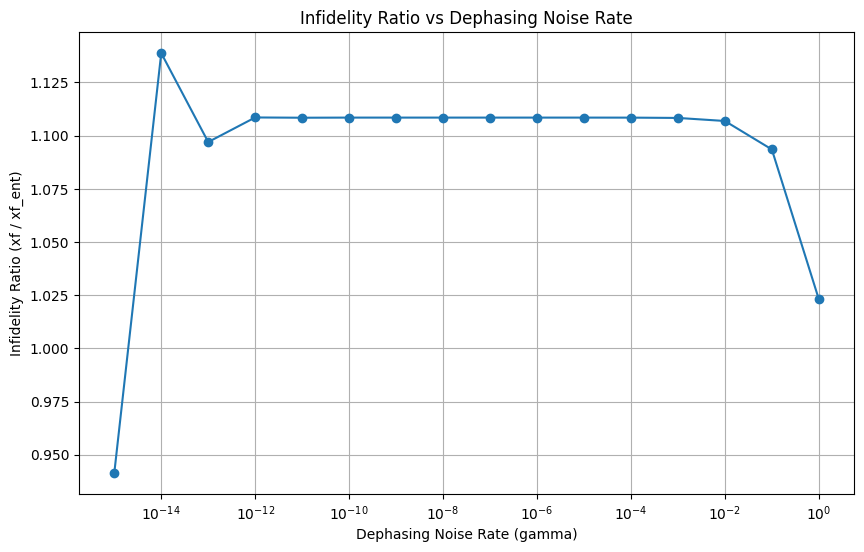

In [ ]:
# Repeat for dephasing noise

def local_dephasing_ops_2q(gamma):
    pref = np.sqrt(gamma / 4.0)
    return np.array([
        pref * np.kron(Z, I2),
        pref * np.kron(I2, Z),
    ], dtype=np.complex128)

final_infidelities_xf_dephasing = []
final_infidelities_xf_ent_dephasing = []

for gamma in noise_rates:
    L0 = local_dephasing_ops_2q(gamma)
    sys_noisy = sys.add_lindblad_terms(L0=L0)
    driven_sys_noisy = sys_noisy.pulse_form(Lindblad_pulse_function)

    final_state_noisy_xf = driven_sys_noisy.propagate(xf)
    final_state_noisy_xf_ent = driven_sys_noisy.propagate(xf_ent)

    final_infidelity_xf = dm_infidelity(final_state_noisy_xf, target_state)
    final_infidelity_xf_ent = dm_infidelity(final_state_noisy_xf_ent, target_state)

    final_infidelities_xf_dephasing.append(final_infidelity_xf)
    final_infidelities_xf_ent_dephasing.append(final_infidelity_xf_ent)

plt.figure(figsize=(10, 6))
plt.plot(noise_rates, np.array(final_infidelities_xf_dephasing) - infidelity_baseline_xf, marker='o', label='Final Infidelity')
plt.plot(noise_rates, np.array(final_infidelities_xf_ent_dephasing) - infidelity_baseline_xf_ent, marker='o', label='Final Infidelity (entanglement-constrained)')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Dephasing Noise Rate (gamma)')
plt.ylabel('Final Infidelity')
plt.title('Final Infidelity vs Dephasing Noise Rate')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(noise_rates, (np.array(final_infidelities_xf_dephasing) - infidelity_baseline_xf) / (np.array(final_infidelities_xf_ent_dephasing) - infidelity_baseline_xf_ent), marker='o')
plt.xscale('log')
plt.xlabel('Dephasing Noise Rate (gamma)')
plt.ylabel('Infidelity Ratio (xf / xf_ent)')
plt.title('Infidelity Ratio vs Dephasing Noise Rate')
plt.grid()
plt.show()

Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.


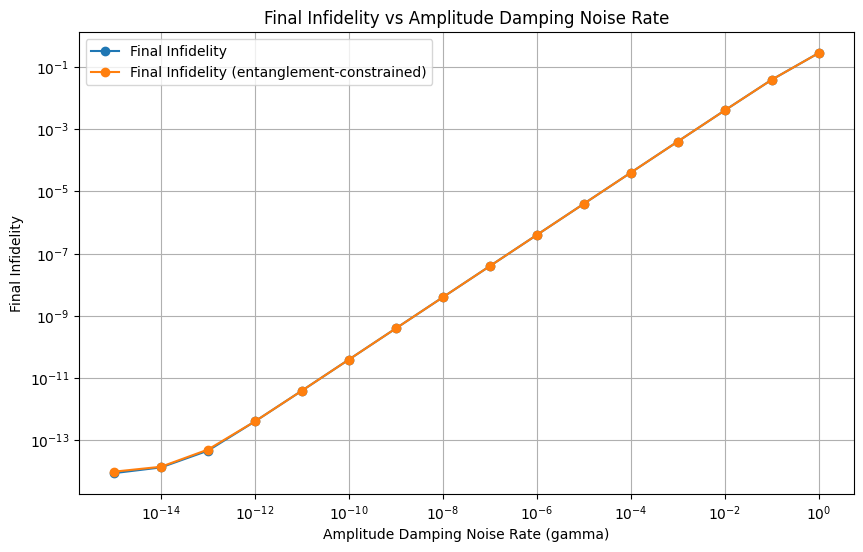

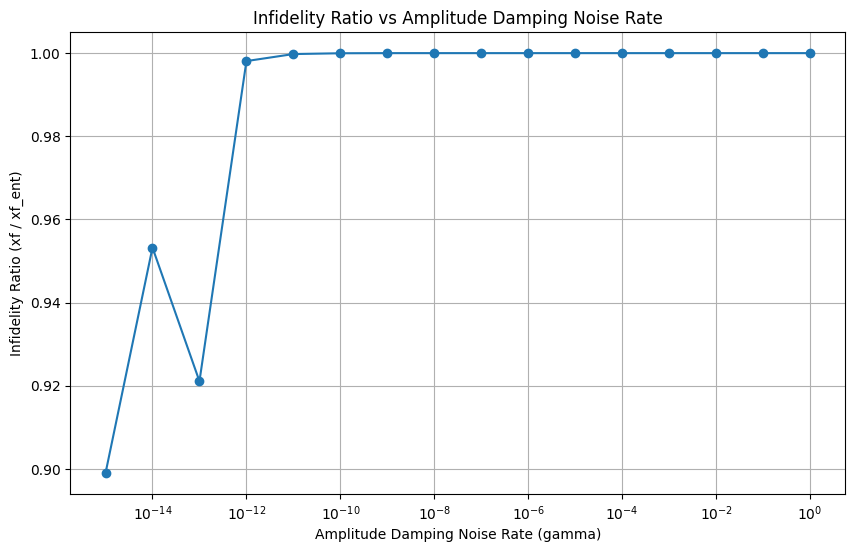

In [ ]:
# Amplitude damping noise

def local_amplitude_damping_ops_2q(gamma):
    pref = np.sqrt(gamma/4)
    return np.array([
        pref * np.kron(Splus, I2),
        pref * np.kron(I2, Splus),
    ], dtype=np.complex128)

final_infidelities_xf_amp_damp = []
final_infidelities_xf_ent_amp_damp = []

for gamma in noise_rates:
    L0 = local_amplitude_damping_ops_2q(gamma)
    sys_noisy = sys.add_lindblad_terms(L0=L0)
    driven_sys_noisy = sys_noisy.pulse_form(Lindblad_pulse_function)

    final_state_noisy_xf = driven_sys_noisy.propagate(xf)
    final_state_noisy_xf_ent = driven_sys_noisy.propagate(xf_ent)

    final_infidelity_xf = dm_infidelity(final_state_noisy_xf, target_state)
    final_infidelity_xf_ent = dm_infidelity(final_state_noisy_xf_ent, target_state)

    final_infidelities_xf_amp_damp.append(final_infidelity_xf)
    final_infidelities_xf_ent_amp_damp.append(final_infidelity_xf_ent)

plt.figure(figsize=(10, 6))
plt.plot(noise_rates, np.array(final_infidelities_xf_amp_damp) - infidelity_baseline_xf, marker='o', label='Final Infidelity')
plt.plot(noise_rates, np.array(final_infidelities_xf_ent_amp_damp) - infidelity_baseline_xf_ent, marker='o', label='Final Infidelity (entanglement-constrained)')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Amplitude Damping Noise Rate (gamma)')
plt.ylabel('Final Infidelity')
plt.title('Final Infidelity vs Amplitude Damping Noise Rate')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(noise_rates, (np.array(final_infidelities_xf_amp_damp) - infidelity_baseline_xf) / (np.array(final_infidelities_xf_ent_amp_damp) - infidelity_baseline_xf_ent), marker='o')
plt.xscale('log')
plt.xlabel('Amplitude Damping Noise Rate (gamma)')
plt.ylabel('Infidelity Ratio (xf / xf_ent)')
plt.title('Infidelity Ratio vs Amplitude Damping Noise Rate')
plt.grid()
plt.show()

### Optimise with noise

In [18]:
res = minimize(
    driven_sys_noisy.gradient, x0, args=(observable,),
    jac=True, bounds=bounds, method="L-BFGS-B",
    options={"maxiter": int(config.maxiter), "gtol": float(config.gtol)},
)
gn = float(np.linalg.norm(res.jac)) if res.jac is not None else 0.0
S = _cost_entropy(driven_sys_noisy, res.x, S_max=float(config.S_max), ent_traj_fn=von_neumann_entropy_traj)
print(f"Infidelity: I={res.fun:.3e}, nit={res.nit}, success={res.success}, grad_norm={gn:.3e}, S={S:.3e}")

xf = res.x
infidelity_baseline_xf = float(res.fun)
print(xf)
print(infidelity_baseline_xf)

TypeError: switching_function(): incompatible function arguments. The following argument types are supported:
    1. (self: py_ste.evolvers.Evolver, ctrl_amp: typing.Annotated[numpy.typing.NDArray[numpy.complex128], "[m, n]"], state: typing.Annotated[numpy.typing.NDArray[numpy.complex128], "[m, 1]"], dt: float, cost: typing.Annotated[numpy.typing.NDArray[numpy.complex128], "[1, n]"]) -> tuple[complex, typing.Annotated[numpy.typing.NDArray[numpy.complex128], "[m, n]"]]

Invoked with: <py_ste.evolvers.Evolver object at 0x165060970>, array([[0.        +0.j, 2.67051585+0.j],
       [0.        +0.j, 1.45545941+0.j],
       [0.        +0.j, 0.15075047+0.j],
       [0.        +0.j, 8.05599172+0.j],
       [0.        +0.j, 0.45857355+0.j],
       [0.        +0.j, 1.70645391+0.j],
       [0.        +0.j, 2.58001635+0.j],
       [0.        +0.j, 3.44768885+0.j],
       [0.        +0.j, 4.97472783+0.j],
       [0.        +0.j, 4.68429769+0.j],
       [0.        +0.j, 7.0415909 +0.j],
       [0.  

In [19]:
import numpy as np
import tensorflow as tf
from qugradlab.systems.semiconducting.esr import SpinChain

psi0 = np.array([0.0, 1.0, 0.0, 0.0], dtype=np.complex128)  # |01> state
dt = 1e-2 * 1e-3  # timestep in μs to match J in MHz
n_steps = 1000
x_random = np.random.uniform(-1.0, 1.0, size=(n_steps, 1))  # random J amplitudes for testing

# Define SpinChain with QuGradLab

sys = SpinChain(
    spins=2,
    zeeman_splittings=np.array([0.0, 0.0]),
    max_drive_strength=0.0,
    J_max=10.0,  # MHz
    J_min=0.0,
    feromagnetic=False,
    use_graph=True,
)

def convert_dtype(np_array) -> tf.Tensor: 
    return tf.cast(tf.convert_to_tensor(np_array), dtype=tf.complex128)

def pulse_function(x):
    drive_amps = convert_dtype(np.zeros((n_steps, 2), dtype=np.complex128))      # drive amplitudes (disabled, 2 because there are 2 qubits so 2 channels)
    drive_frequencies = convert_dtype(np.array([0.0, 0.0], dtype=np.complex128)) # drive frequencies (disabled)
    x = convert_dtype(tf.reshape(x, (n_steps, 1)))                               # 1 because only 1 J channel for 2 qubits
    initial_state = convert_dtype(psi0)                   # density matrix for |01><01|
    return (
        drive_amps,      
        drive_frequencies,   
        x,                                 
        initial_state,      
        dt * 2 * np.pi,          
    )

driven_sys = sys.pulse_form(pulse_function)

final_state = driven_sys.propagate(x_random)
print(np.round(final_state, 3))

psi1 = final_state  # update initial state to the final state from the first propagation

sys2 = SpinChain(
    spins=2,
    zeeman_splittings=np.array([0.0, 0.0]),
    max_drive_strength=0.0,
    J_max=0.0,  # MHz
    J_min=-10.0,
    feromagnetic=False,
    use_graph=True,
)
def pulse_function2(x):
    drive_amps = convert_dtype(np.zeros((n_steps, 2), dtype=np.complex128))      # drive amplitudes (disabled, 2 because there are 2 qubits so 2 channels)
    drive_frequencies = convert_dtype(np.array([0.0, 0.0], dtype=np.complex128)) # drive frequencies (disabled)
    x = convert_dtype(tf.reshape(x, (n_steps, 1)))                               # 1 because only 1 J channel for 2 qubits
    initial_state = convert_dtype(psi1)                   # density matrix for |01><01|
    return (
        drive_amps,      
        drive_frequencies,   
        x,                                 
        initial_state,      
        dt * 2 * np.pi,          
    )
driven_sys2 = sys2.pulse_form(pulse_function2)

x_reverse = np.flip(x_random, axis=0)
final_state_reverse = driven_sys2.propagate(x_reverse)
print(np.round(final_state_reverse, 3))

Tracing control amplitude graph.
[-0.   +0.j     0.985+0.078j  0.012-0.157j -0.   +0.j   ]
Tracing control amplitude graph.
[-0.-0.j     1.+0.001j  0.-0.001j -0.-0.j   ]
